# Template-subtracted photometry with AutoPhOT

This notebook measures the brightness of a supernova after the light of its host galaxy has been removed.

SN 2022mop is a type-IIn supernova at redshift 0.017, a kind that can stay bright for years because its ejecta keep colliding with gas the star shed before exploding. The supernova sits on top of its host galaxy, so a direct measurement would count galaxy light as supernova light. The workaround is template subtraction: take an image of the same field without the supernova in it (a "template"), align it to the new image, match the blur and brightness, and subtract. What remains is the transient.

The bundled example is a 300 s i-band exposure taken with the SLT telescope on 2025-01-04. Running this notebook reduces the image, subtracts a Pan-STARRS template, measures the supernova on the difference image, and calibrates the result against catalog stars. The run takes a couple of minutes.

Two folders under `examples/` supply the inputs:

- `example_data/` holds the science image `images.fits` and `templates/ip_template/`, a deep Pan-STARRS i-band reference. The folder stays read-only: the run copies the template into the output tree as `ready_template.fits` and works on the copy.
- `autophot_db/` is the working database. `telescope.yml` tells AutoPhOT how to read each telescope's FITS headers, `tns_objects/` caches target lookups (`2022mop.yml` gives this supernova's coordinates from a saved Transient Name Server record), and `sn2022mop_ps1_catalog.csv` holds the calibration stars.

No network is needed. The catalog file contains Pan-STARRS mean magnitudes over the science field, so the template and the science image share one magnitude system.

## What you need

- AutoPhOT importable in this kernel (`pip install .` from the repository, or `conda install -c conda-forge -c astro-sean autophot`).
- SExtractor, a standard source-detection program, on `PATH` as `sex` or `source-extractor`. Without it the run falls back to slower pure-Python detection and the subtraction drops to HOTPANTS.
- The Python packages `sfft` (with `numba`), `reproject`, and `astroalign`; a `hotpants` binary on `PATH` is the fallback subtraction engine.
- Start the notebook from `examples/`; the paths below are relative to it.

## Setup

`AutomatedPhotometry.load()` returns the full configuration as one nested dictionary. The cells below set only the keys this run needs; every other key keeps its default from `autophot/data/default_input.yml`, which documents every parameter.

In [1]:
import os
import shutil
import sys
from pathlib import Path

try:
    from autophot import AutomatedPhotometry
except ModuleNotFoundError:
    # Source checkout without an install: the repo root is the parent of examples/.
    sys.path.insert(0, str(Path.cwd().parent))
    from autophot import AutomatedPhotometry

import autophot
print(f"autophot {autophot.__version__} -> {autophot.__file__}")

autophot_input = AutomatedPhotometry.load()

examples_dir = Path.cwd()
if not (examples_dir / "example_data").is_dir():
    raise FileNotFoundError(
        f"example_data not found under {examples_dir}; start the notebook from examples/"
    )

autophot 1.5.1 -> /home/sbrennan/Documents/autophot_object/autophot/__init__.py


                                A U T O P H O T
                                     v1.5.1
                                 Configuration



Configuration loaded in 0.148 seconds.


In [2]:
# SExtractor is an external binary, not a Python package. When it lives in a
# conda environment that is not on PATH, point the run at it here.
if not (shutil.which("sex") or shutil.which("source-extractor")):
    for _bin in sorted(Path.home().glob("*conda3/envs/*/bin")):
        if (_bin / "sex").exists() or (_bin / "source-extractor").exists():
            os.environ["PATH"] = str(_bin) + os.pathsep + os.environ["PATH"]
            print(f"added {_bin} to PATH")
            break
    else:
        print("[warn] SExtractor not found; the run will use the slower Python fallback")

## 1. Point AutoPhOT at the data

Two paths do most of the work: `fits_dir` says where the images live, `wdir` says where the telescope database and caches live. Everything the run produces goes under `<fits_dir>_REDUCED/`, so the inputs are never modified.

| Key | Value | What it does |
|---|---|---|
| `fits_dir` | `example_data/` | Folder scanned recursively for science FITS files. A `templates/` folder inside it supplies reference images; each one is copied to `<fits_dir>_REDUCED/ready_templates/` and processed there. Set as an absolute path, since the pipeline changes directory while it runs. |
| `wdir` | `autophot_db/` | Working folder for the telescope database and the TNS and catalog caches. |
| `outdir_name` | `'REDUCED'` | Suffix of the output folder. |
| `target_name` | `'2022mop'` | Resolved through `<wdir>/tns_objects/2022mop.yml`, then TNS or SIMBAD when online. For a position with no catalog name, use `target_ra`/`target_dec` in degrees instead. |
| `selected_filters` | `['i']` | Filter bands to process; an empty list takes every band found. |
| `restart` | `False` | Skips images that already produced an `Output_*.csv`. Set `True` to reprocess everything. |
| `rng_seed` | `42` | Seed for the limiting-magnitude injection trials, so the reported limit is reproducible. |

In [3]:
# Absolute paths - the pipeline os.chdir()s into each output directory
# while running, so relative locations would resolve against the wrong cwd.
autophot_input['fits_dir'] = str(examples_dir / 'example_data')
autophot_input['wdir'] = str(examples_dir / 'autophot_db')
autophot_input['outdir_name'] = 'REDUCED'

autophot_input['target_name'] = '2022mop'

autophot_input['selected_filters'] = ['i']
autophot_input['restart'] = False
autophot_input['rng_seed'] = 42

## 2. Calibration catalog

Magnitudes measured off a detector are relative. To put them on a standard scale, AutoPhOT measures catalog stars in the image and fits the offset between its instrumental magnitudes and their published ones; that offset is the *zeropoint*. This example supplies the catalog as a local CSV holding Pan-STARRS mean magnitudes for about 11,000 stars covering the field, in the same photometric system as the template. No network needed.

A custom CSV needs `ra` and `dec` columns plus `<band>`/`<band>_err` magnitude columns; this one carries `i`, `g`, and `r`.

On your own field you can skip the file: `use_catalog='auto'` or `'panstarrs'` downloads a catalog once into `<wdir>/catalog_queries/`, and later runs reuse it.

| Key | Value | What it does |
|---|---|---|
| `catalog.use_catalog` | `'custom'` | `'auto'`, a survey name, a per-band dictionary, or `'custom'` for a local CSV. |
| `catalog.catalog_custom_fpath` | `autophot_db/sn2022mop_ps1_catalog.csv` | The CSV `custom` reads. |

In [4]:
autophot_input['catalog']['use_catalog'] = 'custom'
autophot_input['catalog']['catalog_custom_fpath'] = str(
    examples_dir / 'autophot_db' / 'sn2022mop_ps1_catalog.csv'
)

## 3. Astrometry

The WCS (world coordinate system) stored in a FITS header converts pixel positions to sky coordinates; catalog matching and template alignment both depend on it. This science frame already has a reliable WCS, so `redo_wcs` stays off and no solver runs. Turn it on for images without good astrometry; that path needs `solve-field` from astrometry.net, or `scamp`/`swarp` with `solver='scamp'`.

In [5]:
autophot_input['wcs']['redo_wcs'] = False

## 4. Template subtraction

AutoPhOT looks for templates under `fits_dir/templates/<band>_template/`; the bundled `ip_template/` is the old name for the i-band folder and still works. The input folder is never modified: each template is staged as `ready_template.fits` under `<fits_dir>_REDUCED/ready_templates/` and processed there. With no template on disk, `download_templates='panstarrs'` makes the pipeline fetch one.

Subtraction also needs the two frames to share a point spread function (PSF, the blur shape the atmosphere and optics give every star); `forceconv` below controls which frame is blurred to match the other.

| Key | Value | What it does |
|---|---|---|
| `do_subtraction` | `True` | Turn the stage on. |
| `alignment_method` | `'reproject'` | How the template is registered onto the science frame. Both images here have good WCS, so pure WCS resampling is enough. `'spalipy'` (the default) handles harder cases; `'astroalign'`, `'scamp'`, `'swarp'`, `'tweakwcs'` are the other options. |
| `method` | `'sfft'` | Subtraction engine: `'sfft'`, `'hotpants'`, `'zogy'`, or `'auto'`. SFFT needs `sex` and `numba`; on failure the pipeline retries with looser flags, then falls back to HOTPANTS. |
| `forceconv` | `'REF'` | Which frame is convolved to match the other. `'REF'` blurs the (sharper) reference down to the science PSF, so the science PSF survives on the difference image and the ePSF model built earlier applies directly. |
| `sfft_backend` | `'numpy'` | `'cupy'` runs on a CUDA GPU. |
| `kernel_order` | `'0'` | Spatial polynomial degree of the matching kernel; `'auto'` raises it only when the field has enough sources. |

In [6]:
autophot_input['template_subtraction']['do_subtraction'] = True
autophot_input['template_subtraction']['alignment_method'] = 'reproject'
autophot_input['template_subtraction']['method'] = 'sfft'
autophot_input['template_subtraction']['forceconv'] = 'REF'
autophot_input['template_subtraction']['sfft_backend'] = 'numpy'
autophot_input['template_subtraction']['kernel_order'] = '0'

## 5. Run

`run_photometry` processes the staged template first, then the science image, then aligns and subtracts the pair and measures the target on the difference image. One frame takes a couple of minutes. The return value is the path of the combined output CSV, and the full log also lands in `LOG_<image>.log` inside each image's output folder. `nCPU` and `nGPU` only matter for runs with many images.

The log is long; the summary block near the end is the part to read. It reports the detection call, magnitude, zeropoint, and limiting magnitude for the image.

In [7]:
autophot_input['nCPU'] = 1
autophot_input['nGPU'] = 0
autophot_input['global_verbose_level'] = 1

loc = AutomatedPhotometry.run_photometry(
    default_input=autophot_input
)
print(loc)



                                A U T O P H O T
                                     v1.5.1
                                 photometry run



Report any issues at: https://github.com/Astro-Sean/autophot/issues


Available filters: g, i, r



TNS check


Using cached TNS information for 2022mop.



TNS info (cache):
  Name ............ SN2022mop
  Source .......... cache
  Type ............ SN IIn
  RA / Dec ........ 352.713417 / -2.942750 deg
  RA / Dec (hms) ... 23:30:51.220 / -02:56:33.90
  Redshift ........ 0.017219
  Discovered ...... 2022-06-11 13:59:06.144
  Discovery mag ... 20.45 (w)
  Internal IDs .... PS22fhf, ZTF22aanyxmg, ATLAS24saw, Gaia25aaf, GOTO25gj


... (120 outputs left out)


Collect photometry: /home/sbrennan/Documents/autophot_object/examples/example...


Concatenated 1 rows of tabular data into '/home/sbrennan/Documents/autophot_object/
       examples/example_data_REDUCED/LightCurve_Output.csv'.


Photometry pipeline completed in 169.222 seconds.


/home/sbrennan/Documents/autophot_object/examples/example_data_REDUCED/LightCurve_Output.csv


## 6. Read the output table

`LightCurve_Output.csv` holds one row per image. The columns that matter:

- `is_detection`: the pipeline's detection call, based on the signal-to-noise ratio (S/N), the fitted profile shape, and a false-alarm probability measured on the same image.
- `mag_psf`, `mag_psf_err`: the calibrated magnitude from PSF fitting on the difference image.
- `snr_psf`, `prob_detect`, `mf_snr`, `reduced_chi2`: the evidence behind the detection call.
- `zp_psf`, `zp_psf_err`, `zp_psf_reliable`, `zp_psf_flags`: the zeropoint and its quality flags.
- `limiting_mag`, `limiting_mag_5s2n`: how faint the pipeline could have detected, used when an epoch is a non-detection.

In [8]:
import pandas as pd

if not loc:
    raise RuntimeError("run_photometry returned no output; check the log above")
lc = pd.read_csv(loc)
cols = [
    'mjd', 'filter', 'is_detection', 'mag_psf', 'mag_psf_err', 'snr_psf',
    'prob_detect', 'reduced_chi2', 'zp_psf', 'zp_psf_err', 'limiting_mag',
]
print(lc[cols].T.to_string())
print('\nZP flags:', lc['zp_psf_flags'].iloc[0])

                         0
mjd           60679.502593
filter                   i
is_detection          True
mag_psf          16.591911
mag_psf_err       0.060817
snr_psf          19.232036
prob_detect            1.0
reduced_chi2      1.279426
zp_psf           21.581514
zp_psf_err        0.022622
limiting_mag     20.784639

ZP flags: nan


## 7. Inspect the diagnostic plots

Each processed image gets a folder under `example_data_REDUCED/` with FITS products, logs, and quality plots; the staged template's products sit under `example_data_REDUCED/ready_templates/`. The plots below are the ones to check after a subtraction run.

In [9]:
from IPython.display import Image, display

image_out = next(Path(loc).parent.glob('*/Output_*.csv')).parent

def show(pattern):
    for p in sorted(image_out.glob(pattern)):
        display(Image(filename=str(p)))

### Subtraction check

Three views of the subtraction: the science image, the template aligned onto it, and their difference, each with a zoomed inset at the supernova position. Cyan boxes mark the stars used to match the frames; magenta hatching is masked area, mostly the thin border where the template does not reach.

In the difference panel the host galaxy has cancelled out and a compact positive blob sits at the target position: that leftover flux is the supernova. Bright-dark pairs (dipoles) or rings around ordinary stars would mean the kernel misjudged the blur difference; here the field goes to noise except at the target.

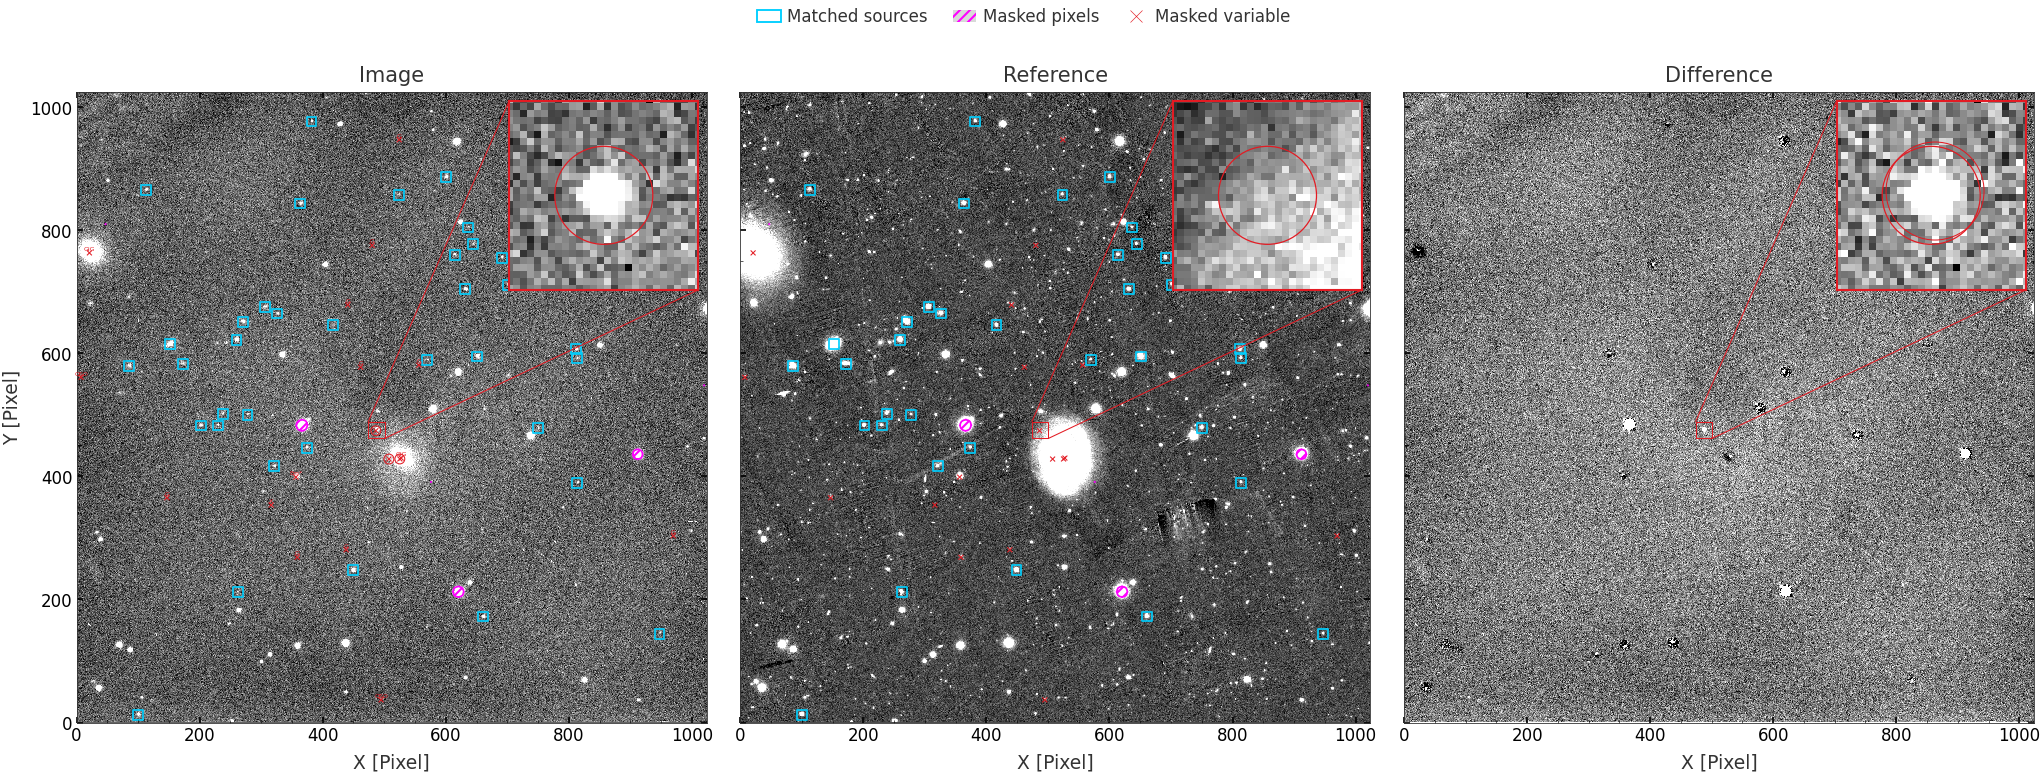

In [10]:
show('Subtraction_Check_*.png')

### Zeropoint

Each point is a calibration star: its catalog magnitude against the instrumental magnitude AutoPhOT measured. The dashed lines fit with the slope held at exactly 1; the offset they measure is the zeropoint. The dotted lines fit the slope freely, and a free slope straying far from 1 would signal a linearity or catalog problem. Here 36 calibrators give fitted slopes of 1.001 (PSF) and 0.999 (aperture), and the run marks both zeropoints reliable; the zeropoint errors are about 0.02-0.03 mag.

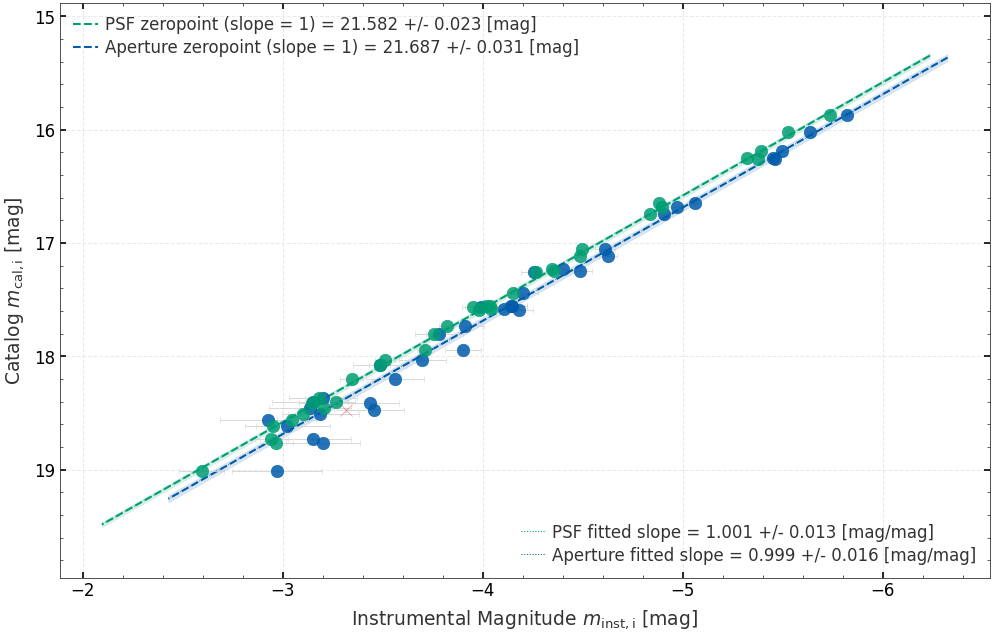

In [11]:
show('Zeropoint_*.png')

### Source check

The science image with its detected sources: PSF candidates in green, catalog calibrators in blue, sources feeding the FWHM estimate in orange. If this panel were nearly empty, the photometry downstream would be thin; check the seeing and the detection thresholds.

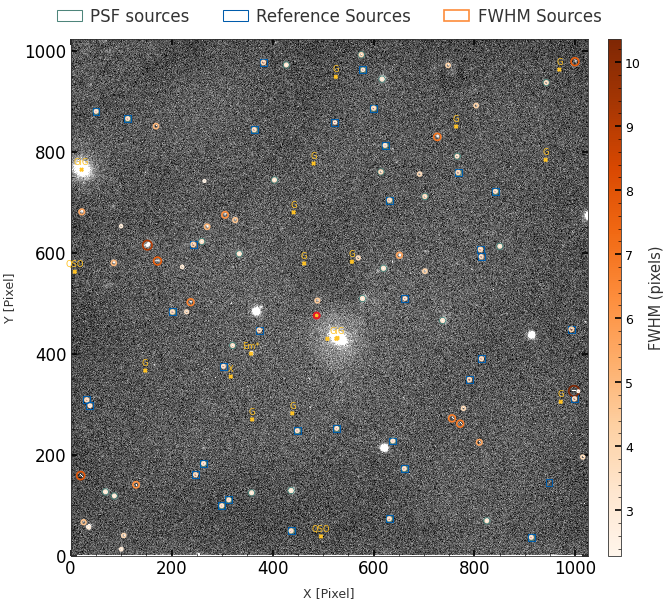

In [12]:
show('Source_Check_*.png')

### Template registration

How accurately the aligned template sits on the science grid. Each arrow is one matched star's residual, magnified to be visible; the panel on the right smooths the residuals into a map. Only 13 stars passed the matching cuts, so the field looks sparse. The legend's quadrant medians are all under half a pixel. A coherent swirl or large arrows would mean the registration is off and the subtraction would leave dipoles.

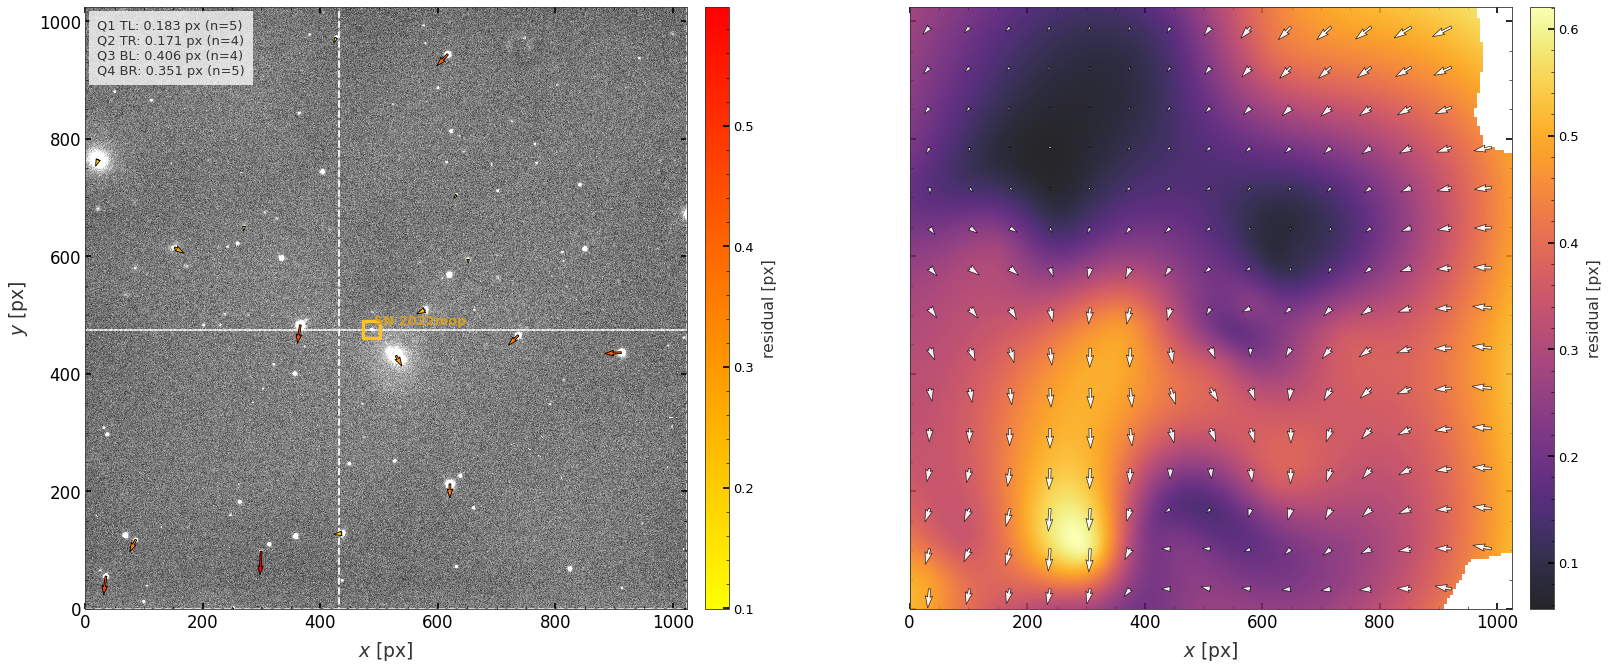

In [13]:
show('Alignment_Vectors_*.png')

### Target PSF fit

Fitting the PSF to the target measures its flux while rejecting the background. Left: the supernova's cutout on the difference image with the fitted center marked. Right: what remains after the fitted model is removed. A good fit leaves flat noise; a ring or a leftover dipole would mean the model is wrong and the flux biased. This fit gave a reduced chi-square of 1.28, close to the ideal value of 1.

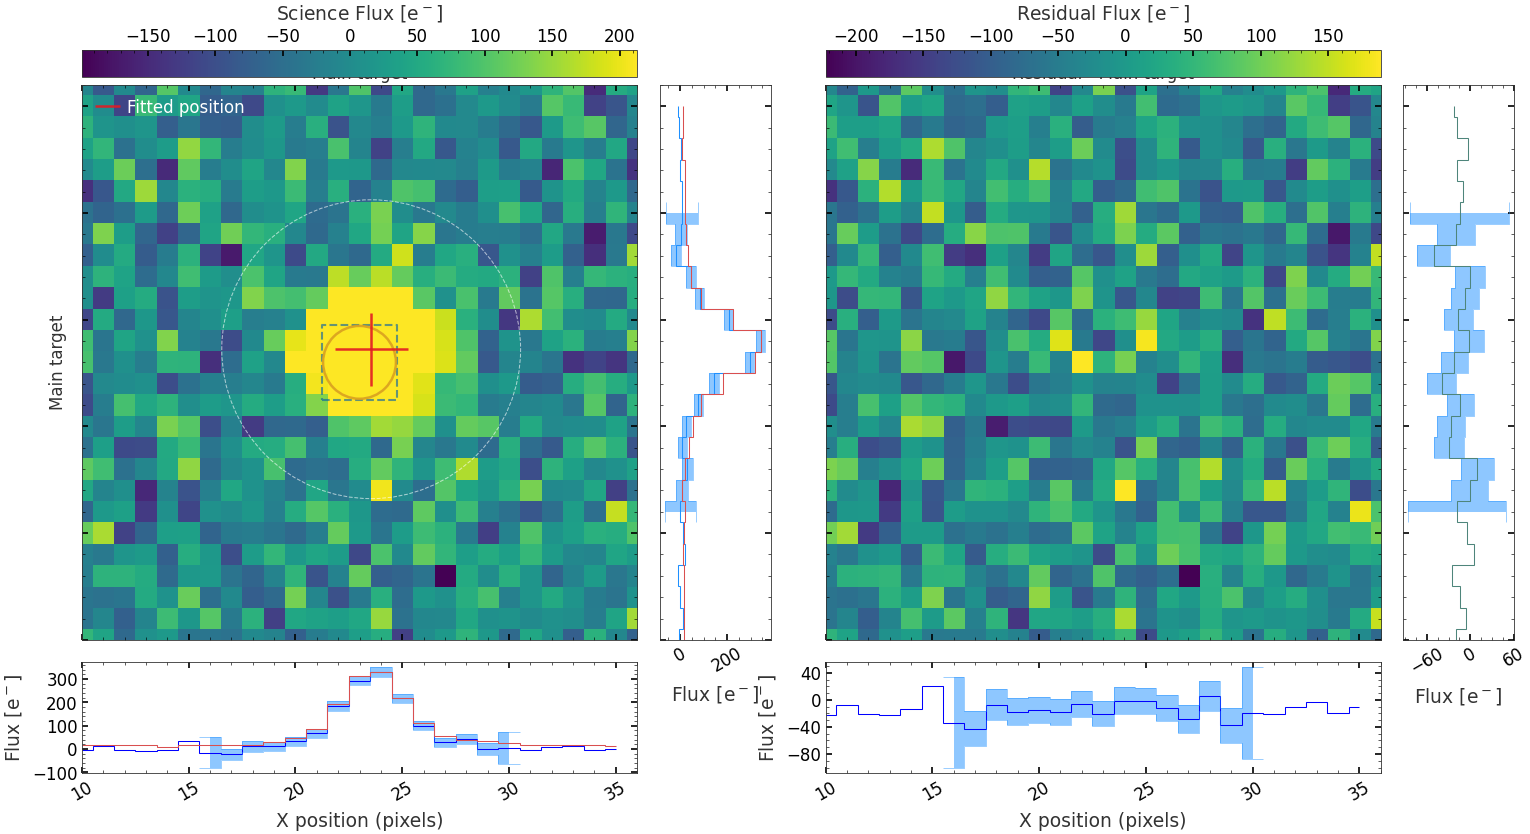

In [14]:
show('PSF_Target_*.png')

### Limiting magnitude

How faint could the supernova be and still be detected? The pipeline answers this by pasting fake stars of known brightness near the target on the difference image and counting how many it recovers. The curve shows the recovered fraction at each injected brightness for two detection thresholds, and the diamonds mark 50% recovery, the standard definition of the limiting magnitude. This image reaches 20.78 mag at S/N >= 3 and 19.73 mag at the stricter S/N >= 5.

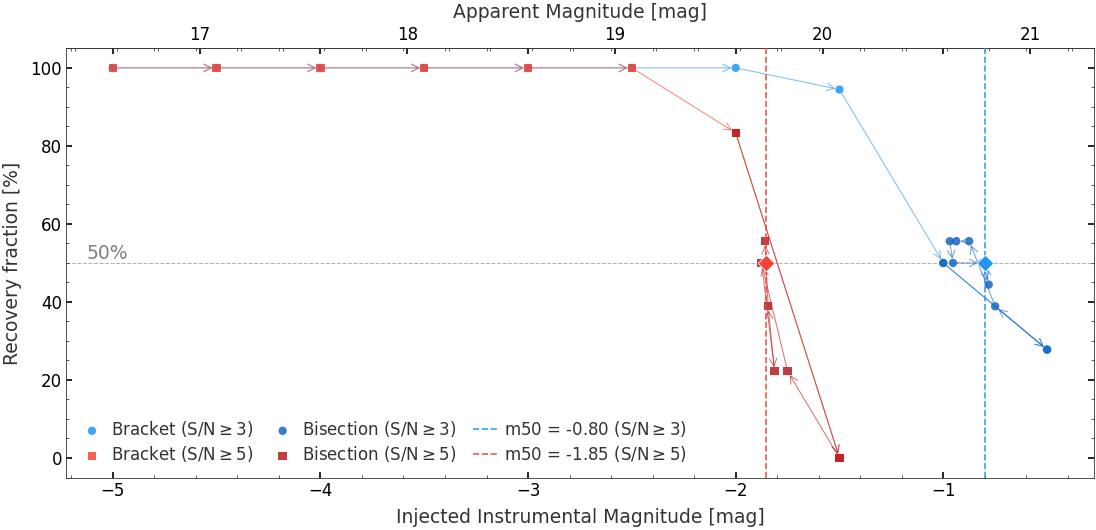

In [15]:
show('Completeness_*.png')

## What happened, and where next

SN 2022mop subtracts to a clean point source at its catalog position: i = 16.59 +/- 0.06 mag at S/N ~ 19, roughly two and a half years after discovery. The difference panel in the subtraction check is the evidence: the host galaxy cancels and only the transient remains.

To run the same reduction on your own data, set `fits_dir` to your images, `target_name` to a TNS-resolvable name (or `target_ra`/`target_dec`), `use_catalog` to `'auto'` or a survey name, and either drop a `<band>_template/` folder under `fits_dir/templates/` or set `download_templates='panstarrs'`. Every parameter is documented in `autophot/data/default_input.yml`.